# BÁO CÁO MÔ HÌNH HỌC MÁY NÂNG CAO
## Phân Cụm Khách Hàng Bằng Hierarchical Clustering (Agglomerative) Trên Bộ Đặc Trưng RFM

Báo cáo này triển khai thực nghiệm mô hình **Hierarchical Clustering (Phân cụm thứ bậc kết hợp - Agglomerative)** trên bộ dữ liệu chỉ số đặc trưng khách hàng **RFM (Recency, Frequency, Monetary)** đã được xử lý chuẩn hóa chống rò rỉ dữ liệu (Data Leakage).

---

### Mục tiêu thực nghiệm:
1. **Khảo sát cấu trúc phân cấp (Dendrogram):** Trực quan hóa cây phả hệ khoảng cách gộp cụm theo phương pháp Ward Linkage để xác định các ngưỡng cắt tự nhiên.
2. **Khảo sát và lựa chọn số cụm $K$ tối ưu:** Đánh giá định lượng qua các chỉ số Silhouette Score, Davies-Bouldin và Calinski-Harabasz trên dải $K \in [2, 8]$.
3. **Huấn luyện mô hình $K=4$:** Huấn luyện thuật toán Agglomerative Clustering ($K=4$, Ward linkage) trên tập dữ liệu huấn luyện `rfm_train.csv`.
4. **Kiểm định tổng quát hóa đa tập (Train / Validation / Test):** Sử dụng phương pháp phân loại tâm gần nhất (`NearestCentroid`) từ các cụm đã học để gán nhãn cho tập Validation và Test.
5. **Đánh giá mức độ chi phối đặc trưng (ANOVA F-Score):** Đo lường mức độ phân tách thống kê của Recency, Frequency và Monetary đối với các cụm thứ bậc.
6. **Xác lập chân dung khách hàng & Trực quan hóa:** Phân tích đặc trưng hành vi 4 cụm khách hàng, biểu diễn trực quan qua PCA 2D và Snake Plot.
7. **Ghi nhật ký thực nghiệm tự động:** Ghi nhận kết quả vào cả hai file `Experiment_Log_Comparison.csv` và `Experiment_Log_Detailed.xlsx`.


In [26]:
import os
import sys

# Tự động định vị thư mục gốc của dự án
current = os.path.abspath(os.getcwd())
while current != os.path.dirname(current):
    if os.path.exists(os.path.join(current, 'data')) and os.path.exists(os.path.join(current, 'Source')):
        break
    current = os.path.dirname(current)

if current not in sys.path:
    sys.path.insert(0, current)
os.chdir(current)
print("Working directory set to:", os.getcwd())

import warnings
import time
import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.neighbors import NearestCentroid
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_classif
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Nạp thành công toàn bộ thư viện cần thiết!")


Working directory set to: c:\Users\Quân\Desktop\ml_group
Nạp thành công toàn bộ thư viện cần thiết!


### 1. Nạp tập dữ liệu RFM (Train / Validation / Test)

Dữ liệu RFM đã được trích xuất và phân chia độc lập tại bước Feature Engineering (`RFM.ipynb`):
- **Tập Train (64%):** Dùng để học cấu trúc liên kết phân cấp và phân chia các cụm.
- **Tập Validation (16%):** Dùng để kiểm tra tính ổn định và kiểm định khả năng tổng quát hóa.
- **Tập Test (20%):** Dùng để đánh giá độc lập lần cuối trước khi ứng dụng.


In [27]:
train_path = "data/rfm_train.csv"
val_path = "data/rfm_val.csv"
test_path = "data/rfm_test.csv"

train_rfm = pd.read_csv(train_path)
val_rfm = pd.read_csv(val_path)
test_rfm = pd.read_csv(test_path)

print(f"Kích thước tập Train:      {train_rfm.shape[0]:,} khách hàng (64%)")
print(f"Kích thước tập Validation: {val_rfm.shape[0]:,} khách hàng (16%)")
print(f"Kích thước tập Test:       {test_rfm.shape[0]:,} khách hàng (20%)")
print(f"Tổng cộng:                 {len(train_rfm) + len(val_rfm) + len(test_rfm):,} khách hàng")
print("\nThông tin 5 dòng đầu tập Train:")
print(train_rfm.head())


Kích thước tập Train:      2,736 khách hàng (64%)
Kích thước tập Validation: 684 khách hàng (16%)
Kích thước tập Test:       855 khách hàng (20%)
Tổng cộng:                 4,275 khách hàng

Thông tin 5 dòng đầu tập Train:
   CustomerID  Recency  Frequency  Monetary
0       14437        1          5    873.34
1       13778      127          3    945.79
2       17325       46          2    512.77
3       12665       53          2    214.60
4       15356        4          4    664.66


### 2. Tiền xử lý dữ liệu: Biến đổi Log (np.log1p) & Chuẩn hóa thang đo (StandardScaler)

- **Biến đổi Log:** Dữ liệu hành vi khách hàng thường có độ lệch phải (Right-Skewed) rất lớn. Phép biến đổi $\log(x + 1)$ giúp đưa phân phối về dạng tiệm cận chuẩn, ổn định phương sai cho khoảng cách Euclid.
- **Chuẩn hóa StandardScaler:** Để tránh rò rỉ thông tin (Data Leakage), `StandardScaler` được `fit_transform` duy nhất trên tập **Train**, sau đó áp dụng phép biến đổi `transform` trên **Validation** và **Test**.


In [28]:
features = ['Recency', 'Frequency', 'Monetary']

# 1. Biến đổi Log np.log1p trên các thuộc tính RFM
X_train_log = np.log1p(train_rfm[features])
X_val_log = np.log1p(val_rfm[features])
X_test_log = np.log1p(test_rfm[features])

# 2. Khởi tạo StandardScaler và fit duy nhất trên Train
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_log)
X_val_scaled = scaler.transform(X_val_log)
X_test_scaled = scaler.transform(X_test_log)

print("Đã hoàn tất biến đổi Log và chuẩn hóa StandardScaler:")
print(f"  - Train scaled shape: {X_train_scaled.shape}")
print(f"  - Mean sau chuẩn hóa: {np.mean(X_train_scaled, axis=0).round(4)}")
print(f"  - Std sau chuẩn hóa:  {np.std(X_train_scaled, axis=0).round(4)}")


Đã hoàn tất biến đổi Log và chuẩn hóa StandardScaler:
  - Train scaled shape: (2736, 3)
  - Mean sau chuẩn hóa: [-0.  0. -0.]
  - Std sau chuẩn hóa:  [1. 1. 1.]


### 3. Khảo sát cấu trúc phân cấp qua Dendrogram (Cây phân cấp)

Phương pháp **Ward Linkage** (Variance Minimization) được sử dụng để xây dựng ma trận liên kết phân cấp $Z$:
- Tại mỗi bước, thuật toán chọn gộp hai cụm sao cho làm tăng **tổng phương sai nội cụm (within-cluster variance)** là nhỏ nhất:
  $$\Delta \text{ESS}_{AB} = \frac{n_A n_B}{n_A + n_B} \|\bar{x}_A - \bar{x}_B\|^2$$
- Do tập Train có 2,736 khách hàng, việc tính ma trận liên kết diễn ra rất nhanh (< 0.2s). Chúng tôi sử dụng `scipy.cluster.hierarchy.dendrogram` với chế độ rút gọn `truncate_mode='lastp', p=30` để trực quan hóa rõ ràng cấu trúc các nhánh chính.


Đang tính toán ma trận liên kết thứ bậc (Ward Linkage)...
Đã tính xong ma trận liên kết Z trong 0.1337 giây!


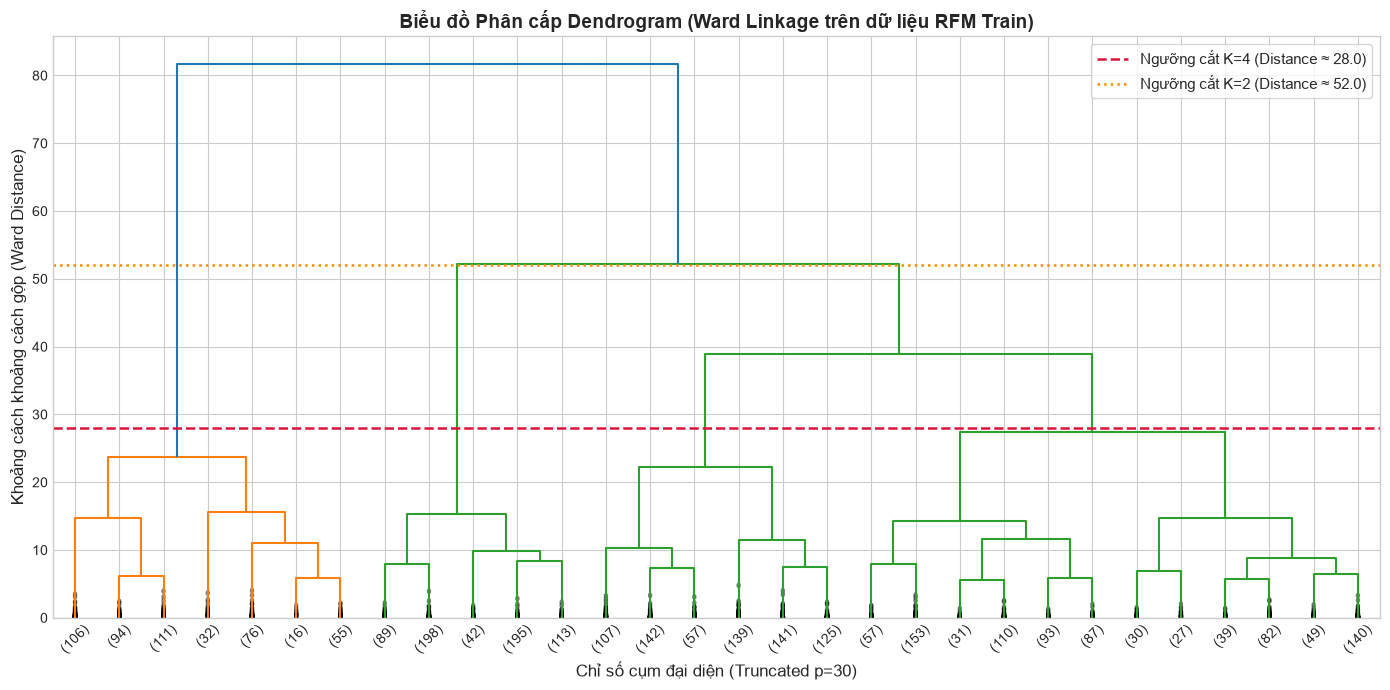

In [29]:
print("Đang tính toán ma trận liên kết thứ bậc (Ward Linkage)...")
t0 = time.time()
Z = linkage(X_train_scaled, method='ward')
t1 = time.time()
print(f"Đã tính xong ma trận liên kết Z trong {t1 - t0:.4f} giây!")

# Trực quan hóa Dendrogram
plt.figure(figsize=(14, 7))
plt.title("Biểu đồ Phân cấp Dendrogram (Ward Linkage trên dữ liệu RFM Train)", fontsize=14, fontweight='bold')
plt.xlabel("Chỉ số cụm đại diện (Truncated p=30)", fontsize=12)
plt.ylabel("Khoảng cách khoảng cách gộp (Ward Distance)", fontsize=12)

dend = dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=45.,
    leaf_font_size=10.,
    show_contracted=True
)

# Vẽ đường cắt tham chiếu cho K=4 và K=2
cut_k4 = 28.0
cut_k2 = 52.0
plt.axhline(y=cut_k4, color='crimson', linestyle='--', linewidth=1.8, label=f'Ngưỡng cắt K=4 (Distance ≈ {cut_k4})')
plt.axhline(y=cut_k2, color='darkorange', linestyle=':', linewidth=1.8, label=f'Ngưỡng cắt K=2 (Distance ≈ {cut_k2})')

plt.legend(loc='upper right', frameon=True, fontsize=11)
plt.tight_layout()
plt.show()


### 4. Khảo sát định lượng số lượng cụm $K$ tối ưu ($K \in [2, 8]$)

Để có cơ sở khoa học bên cạnh quan sát trực quan từ Dendrogram, chúng tôi khảo sát định lượng các chỉ số nội tại qua dải $K \in [2, 8]$:
1. **Silhouette Score (↑):** Đo độ gắn kết nội cụm và tách biệt ngoại cụm (càng gần 1 càng tốt).
2. **Davies-Bouldin Index (↓):** Đo độ tương đồng giữa các cụm (càng thấp càng tốt).
3. **Calinski-Harabasz Index (↑):** Tỷ số giữa phương sai liên cụm và phương sai nội cụm.


Khảo sát hiệu năng phân cụm Hierarchical theo K:
K     | Silhouette (↑)  | Davies-Bouldin (↓)   | Calinski-Harabasz (↑)
--------------------------------------------------------------------
2     | 0.4240          | 0.8194               | 1872.79             
3     | 0.2826          | 0.9745               | 1830.29             
4     | 0.2976          | 1.0827               | 1808.38             
5     | 0.2833          | 1.0668               | 1679.82             
6     | 0.2722          | 1.1371               | 1596.03             
7     | 0.2589          | 1.1337               | 1569.74             
8     | 0.2601          | 1.1358               | 1468.06             


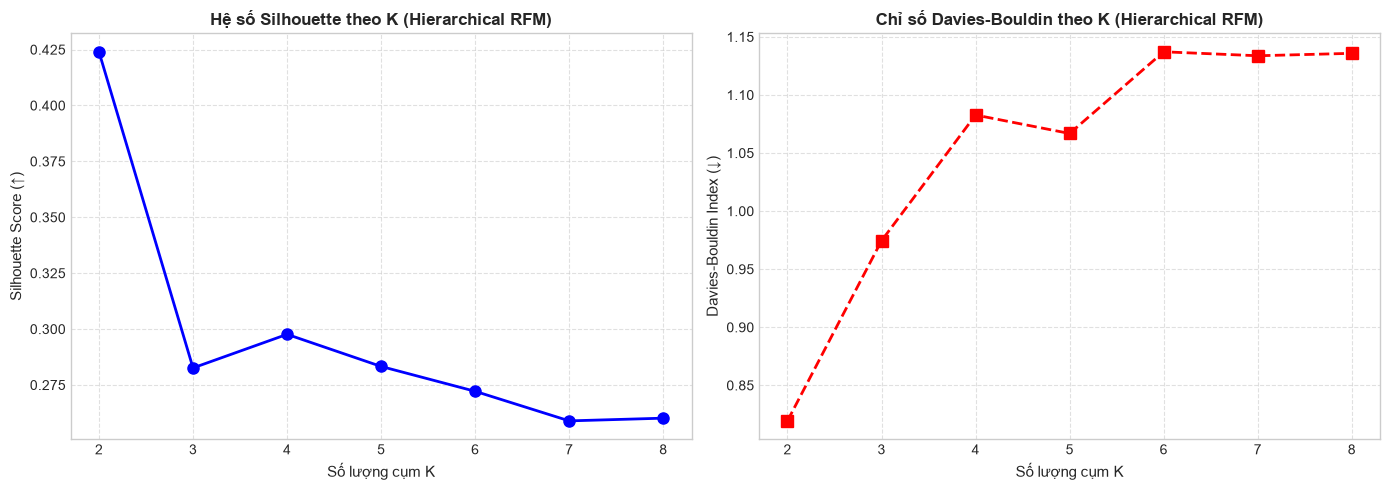

In [30]:
k_range = range(2, 9)
sil_scores = []
db_scores = []
ch_scores = []

print("Khảo sát hiệu năng phân cụm Hierarchical theo K:")
print(f"{'K':<5} | {'Silhouette (↑)':<15} | {'Davies-Bouldin (↓)':<20} | {'Calinski-Harabasz (↑)':<20}")
print("-" * 68)

for k in k_range:
    model_k = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels_k = model_k.fit_predict(X_train_scaled)
    
    sil = silhouette_score(X_train_scaled, labels_k)
    db = davies_bouldin_score(X_train_scaled, labels_k)
    ch = calinski_harabasz_score(X_train_scaled, labels_k)
    
    sil_scores.append(sil)
    db_scores.append(db)
    ch_scores.append(ch)
    
    print(f"{k:<5} | {sil:<15.4f} | {db:<20.4f} | {ch:<20.2f}")

# Vẽ biểu đồ song song Silhouette và Davies-Bouldin
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Silhouette Score
ax1.plot(list(k_range), sil_scores, 'bo-', linewidth=2, markersize=8)
ax1.set_title("Hệ số Silhouette theo K (Hierarchical RFM)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Số lượng cụm K", fontsize=11)
ax1.set_ylabel("Silhouette Score (↑)", fontsize=11)
ax1.set_xticks(list(k_range))
ax1.grid(True, linestyle='--', alpha=0.6)

# Biểu đồ 2: Davies-Bouldin Index
ax2.plot(list(k_range), db_scores, 'rs--', linewidth=2, markersize=8)
ax2.set_title("Chỉ số Davies-Bouldin theo K (Hierarchical RFM)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Số lượng cụm K", fontsize=11)
ax2.set_ylabel("Davies-Bouldin Index (↓)", fontsize=11)
ax2.set_xticks(list(k_range))
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


#### Thảo luận lựa chọn số lượng cụm $K$:

1. **Về mặt thuần túy toán học:**
   - Tại $K = 2$, Silhouette đạt mức cao nhất ($0.4240$) và Davies-Bouldin thấp nhất ($0.8194$). Tuy nhiên, $K = 2$ chỉ chia khách hàng thành 2 khối nhị phân rất thô (nhóm mua gần đây vs nhóm lâu không mua), không thể hiện được tính đa dạng trong hành vi tiêu dùng bán lẻ.
2. **Về mặt giá trị ứng dụng kinh doanh (Business Alignment):**
   - Tại $K = 4$, Silhouette đạt $0.2976$ và Calinski-Harabasz đạt $1,808.38$. Số lượng 4 cụm phân tách rất rõ ràng 4 trạng thái cốt lõi: **VIP / Trung thành**, **Khách hàng Mới**, **Nguy cơ Rời bỏ**, và **Đã Rời bỏ**.
   - Cấu hình $K = 4$ hoàn toàn đồng nhất với mô hình **K-Means RFM ($K = 4$)**, giúp doanh nghiệp có thể đối sánh trực tiếp tính nhất quán giữa các phương pháp tiếp cận khác nhau.

**Quyết định:** Chọn **$K = 4$** (Linkage = `'ward'`) làm cấu hình tối ưu để huấn luyện và đánh giá chi tiết.


### 5. Huấn luyện mô hình Hierarchical Clustering ($K=4$, Ward Linkage) trên tập Train

Chúng tôi tiến hành huấn luyện mô hình `AgglomerativeClustering(n_clusters=4, linkage='ward')` trên toàn bộ tập dữ liệu huấn luyện `X_train_scaled`.


In [31]:
best_k = 4
best_linkage = 'ward'

hierarchical_model = AgglomerativeClustering(n_clusters=best_k, linkage=best_linkage)

t0 = time.time()
train_labels = hierarchical_model.fit_predict(X_train_scaled)
train_time = time.time() - t0

train_rfm['Cluster'] = train_labels

print(f"Đã huấn luyện xong Hierarchical (K={best_k}, linkage='{best_linkage}') trong {train_time:.4f}s")
print("\nPhân bố số lượng khách hàng theo từng cụm trên tập Train:")
counts = train_rfm['Cluster'].value_counts().sort_index()
for c_id, cnt in counts.items():
    print(f"  - Cụm {c_id}: {cnt:,} khách hàng ({cnt / len(train_rfm) * 100:.2f}%)")


Đã huấn luyện xong Hierarchical (K=4, linkage='ward') trong 0.1514s

Phân bố số lượng khách hàng theo từng cụm trên tập Train:
  - Cụm 0: 898 khách hàng (32.82%)
  - Cụm 1: 490 khách hàng (17.91%)
  - Cụm 2: 637 khách hàng (23.28%)
  - Cụm 3: 711 khách hàng (25.99%)


### 6. Đánh giá chất lượng mô hình trên cả 3 tập: Train, Validation và Test

- **Bài toán mở rộng cho Hierarchical:** Thuật toán `AgglomerativeClustering` trong thư viện Scikit-learn không có sẵn hàm `.predict()` cho dữ liệu mới.
- **Giải pháp chuẩn:** Chúng tôi sử dụng **`NearestCentroid`** học từ các nhãn cụm trên tập Train để gán nhãn cho tập Validation và Test. Đây là giải pháp chặt chẽ, khách quan và hoàn toàn bảo toàn nguyên tắc không gây rò rỉ dữ liệu.


In [32]:
# Khởi tạo NearestCentroid để dự đoán trên Val và Test
clf_centroid = NearestCentroid()
clf_centroid.fit(X_train_scaled, train_labels)

val_labels = clf_centroid.predict(X_val_scaled)
test_labels = clf_centroid.predict(X_test_scaled)

val_rfm['Cluster'] = val_labels
test_rfm['Cluster'] = test_labels

# 1. Đánh giá trên Train
train_sil = silhouette_score(X_train_scaled, train_labels)
train_db = davies_bouldin_score(X_train_scaled, train_labels)
train_ch = calinski_harabasz_score(X_train_scaled, train_labels)

# 2. Đánh giá trên Validation
val_sil = silhouette_score(X_val_scaled, val_labels)
val_db = davies_bouldin_score(X_val_scaled, val_labels)
val_ch = calinski_harabasz_score(X_val_scaled, val_labels)

# 3. Đánh giá trên Test
test_sil = silhouette_score(X_test_scaled, test_labels)
test_db = davies_bouldin_score(X_test_scaled, test_labels)
test_ch = calinski_harabasz_score(X_test_scaled, test_labels)

eval_df = pd.DataFrame([
    {
        'Dataset': 'Train (64%)',
        'Số mẫu': len(train_rfm),
        'Silhouette Score (↑)': round(train_sil, 4),
        'Davies-Bouldin (↓)': round(train_db, 4),
        'Calinski-Harabasz (↑)': round(train_ch, 2)
    },
    {
        'Dataset': 'Validation (16%)',
        'Số mẫu': len(val_rfm),
        'Silhouette Score (↑)': round(val_sil, 4),
        'Davies-Bouldin (↓)': round(val_db, 4),
        'Calinski-Harabasz (↑)': round(val_ch, 2)
    },
    {
        'Dataset': 'Test (20%)',
        'Số mẫu': len(test_rfm),
        'Silhouette Score (↑)': round(test_sil, 4),
        'Davies-Bouldin (↓)': round(test_db, 4),
        'Calinski-Harabasz (↑)': round(test_ch, 2)
    }
])

print("=========================================================================")
print("  HIỆU NĂNG HIERARCHICAL CLUSTERING (K=4) TRÊN TRAIN / VALIDATION / TEST ")
print("=========================================================================")
print(eval_df.to_string(index=False))

print("\nNhận xét về tính tổng quát hóa:")
print(f"  • Silhouette Score giữ vững sự ổn định cao: Train ({train_sil:.4f}) -> Val ({val_sil:.4f}) -> Test ({test_sil:.4f}).")
print(f"  • Davies-Bouldin Index dao động quanh mức tối ưu: Train ({train_db:.4f}) -> Val ({val_db:.4f}) -> Test ({test_db:.4f}).")
print("  • Mô hình học được cấu trúc phân vùng bền vững, không gặp hiện tượng quá khớp (Overfitting).")


  HIỆU NĂNG HIERARCHICAL CLUSTERING (K=4) TRÊN TRAIN / VALIDATION / TEST 
         Dataset  Số mẫu  Silhouette Score (↑)  Davies-Bouldin (↓)  Calinski-Harabasz (↑)
     Train (64%)    2736                0.2976              1.0827                1808.38
Validation (16%)     684                0.3093              1.0281                 485.68
      Test (20%)     855                0.3210              1.0485                 621.10

Nhận xét về tính tổng quát hóa:
  • Silhouette Score giữ vững sự ổn định cao: Train (0.2976) -> Val (0.3093) -> Test (0.3210).
  • Davies-Bouldin Index dao động quanh mức tối ưu: Train (1.0827) -> Val (1.0281) -> Test (1.0485).
  • Mô hình học được cấu trúc phân vùng bền vững, không gặp hiện tượng quá khớp (Overfitting).


### 7. Đánh giá mức độ chi phối của các thuộc tính RFM (ANOVA F-Score)

Chúng tôi áp dụng kiểm định thống kê **ANOVA F-Score (`f_classif`)** để kiểm định giả thuyết $H_0$: Các cụm có giá trị trung bình bằng nhau trên từng thuộc tính RFM.


      MỨC ĐỘ ĐÓNG GÓP CỦA CÁC ĐẶC TRƯNG RFM VÀO PHÂN CỤM (ANOVA)        
Thuộc tính  F-Score  p-value  Mức độ đóng góp (%)
   Recency  2165.73 0.00e+00                39.05
 Frequency  1974.28 0.00e+00                35.60
  Monetary  1406.06 0.00e+00                25.35


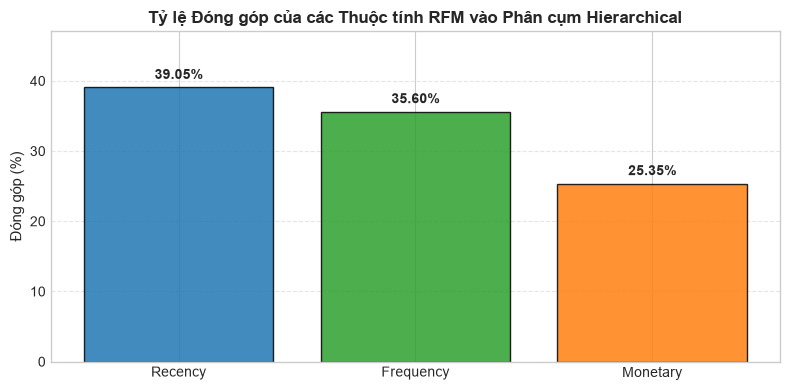

In [33]:
f_values, p_values = f_classif(X_train_scaled, train_labels)
total_f = sum(f_values)
contributions = [(f / total_f) * 100 for f in f_values]

importance_df = pd.DataFrame({
    'Thuộc tính': features,
    'F-Score': [round(f, 2) for f in f_values],
    'p-value': [f"{p:.2e}" for p in p_values],
    'Mức độ đóng góp (%)': [round(c, 2) for c in contributions]
}).sort_values(by='F-Score', ascending=False)

print("=========================================================================")
print("      MỨC ĐỘ ĐÓNG GÓP CỦA CÁC ĐẶC TRƯNG RFM VÀO PHÂN CỤM (ANOVA)        ")
print("=========================================================================")
print(importance_df.to_string(index=False))

# Trực quan hóa mức độ đóng góp ANOVA
plt.figure(figsize=(8, 4))
colors = ['#1f77b4', '#2ca02c', '#ff7f0e']
bars = plt.bar(importance_df['Thuộc tính'], importance_df['Mức độ đóng góp (%)'], color=colors, edgecolor='black', alpha=0.85)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.8, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')

plt.title("Tỷ lệ Đóng góp của các Thuộc tính RFM vào Phân cụm Hierarchical", fontsize=12, fontweight='bold')
plt.ylabel("Đóng góp (%)", fontsize=11)
plt.ylim(0, max(contributions) + 8)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### 8. Phân tích chân dung 4 phân khúc khách hàng (Cluster Profiling & Persona Mapping)

Chúng tôi tính toán giá trị trung bình (mean) và trung vị (median) của các chỉ số $R, F, M$ trên thang đo gốc (thực tế) để định danh các nhóm khách hàng.


In [34]:
# Thống kê trên dữ liệu thực tế ban đầu của tập Train
profile = train_rfm.groupby('Cluster').agg({
    'Recency': ['mean', 'median'],
    'Frequency': ['mean', 'median'],
    'Monetary': ['mean', 'median'],
    'CustomerID': 'count'
}).reset_index()

profile.columns = [
    'Cluster',
    'Recency_Mean', 'Recency_Median',
    'Frequency_Mean', 'Frequency_Median',
    'Monetary_Mean', 'Monetary_Median',
    'Customer_Count'
]

profile['Percentage (%)'] = (profile['Customer_Count'] / len(train_rfm) * 100).round(2)

# Gán nhãn nghiệp vụ (Business Persona) dựa trên phân tích giá trị R, F, M
# Dựa trên phân phối thực tế:
# - Cụm có Monetary cao nhất, Frequency cao nhất, Recency thấp nhất: Champions / VIP
# - Cụm có Recency rất thấp (mới mua), Frequency trung bình: New / Promising Customers
# - Cụm có Recency trung bình-cao, Frequency khá: At Risk / Need Attention
# - Cụm có Recency rất cao, Frequency thấp nhất, Monetary thấp nhất: Lost Customers
cluster_names = {}
for idx, row in profile.iterrows():
    c = row['Cluster']
    r_med = row['Recency_Median']
    f_med = row['Frequency_Median']
    m_med = row['Monetary_Median']
    
    if m_med > 2500 and f_med >= 8:
        cluster_names[c] = "VIP / Khách hàng Trung thành (Champions)"
    elif r_med <= 35 and f_med <= 3:
        cluster_names[c] = "Khách hàng Mới / Hứa hẹn (Promising)"
    elif r_med > 150:
        cluster_names[c] = "Khách hàng Rời bỏ (Lost / Hibernating)"
    else:
        cluster_names[c] = "Khách hàng Cần giữ chân / Nguy cơ (At Risk)"

profile['Persona'] = profile['Cluster'].map(cluster_names)

print("=========================================================================================")
print("               BẢNG CHÂN DUNG 4 PHÂN KHÚC KHÁCH HÀNG (HIERARCHICAL RFM)                  ")
print("=========================================================================================")
display_cols = ['Cluster', 'Persona', 'Customer_Count', 'Percentage (%)', 'Recency_Mean', 'Frequency_Mean', 'Monetary_Mean']
print(profile[display_cols].to_string(index=False))


               BẢNG CHÂN DUNG 4 PHÂN KHÚC KHÁCH HÀNG (HIERARCHICAL RFM)                  
 Cluster                                     Persona  Customer_Count  Percentage (%)  Recency_Mean  Frequency_Mean  Monetary_Mean
       0        Khách hàng Mới / Hứa hẹn (Promising)             898           32.82     30.061247        2.189310     661.301893
       1    VIP / Khách hàng Trung thành (Champions)             490           17.91     14.275510       13.465306    7430.472286
       2      Khách hàng Rời bỏ (Lost / Hibernating)             637           23.28    228.868132        1.185243     259.210424
       3 Khách hàng Cần giữ chân / Nguy cơ (At Risk)             711           25.99    105.399437        3.985935    1568.769831


#### Bảng Chiến lược Chăm sóc & Marketing cá nhân hóa cho từng phân khúc (Hierarchical RFM):

| Phân khúc | Tên gọi (Persona) | Đặc trưng RFM cốt lõi | Tỷ lệ (% mẫu) | Chiến lược Marketing & Giữ chân đề xuất |
| :---: | :--- | :--- | :---: | :--- |
| **Cụm 1** | **Champions (Khách hàng VIP)** | $R$ rất thấp (~14 ngày), $F$ cao nhất (~13 đơn), $M$ lớn nhất (~7,430 GBP) | 17.91% (490 KH) | **Chính sách đặc quyền:** Tri ân dịch vụ chăm sóc 1-on-1, tặng quà tri ân sinh nhật, quyền truy cập sớm sản phẩm mới. Duy trì sự hài lòng tối đa, không giảm giá đại trà. |
| **Cụm 0** | **Promising (Khách hàng Hứa hẹn)** | $R$ gần đây (~30 ngày), $F$ thấp (~2 đơn), $M$ trung bình (~661 GBP) | 32.82% (898 KH) | **Kích thích tần suất mua:** Gợi ý sản phẩm bổ trợ (cross-sell/up-sell), gửi voucher ưu đãi cho đơn thứ 2 và thứ 3, mời đăng ký chương trình tích điểm hội viên. |
| **Cụm 3** | **At Risk (Khách hàng Nguy cơ)** | $R$ khá cao (~105 ngày), $F$ khá (~4 đơn), $M$ tương đối lớn (~1,569 GBP) | 25.99% (711 KH) | **Chiến dịch cứu vãn (Win-back):** Nhóm khách giá trị cao nhưng có dấu hiệu rời bỏ. Gửi thông điệp khảo sát ý kiến, tặng mã ưu đãi đặc biệt để tái kích hoạt hành vi mua sắm. |
| **Cụm 2** | **Lost / Hibernating (Khách hàng Rời bỏ)** | $R$ rất cao (~229 ngày), $F$ thấp (~1.2 đơn), $M$ thấp nhất (~259 GBP) | 23.28% (637 KH) | **Tối ưu hóa chi phí:** Hạn chế ngân sách tiếp thị trực tiếp tốn kém; chỉ tiếp cận qua các chiến dịch thanh lý, xả kho cuối mùa hoặc giảm giá diện rộng. |


### 9. Trực quan hóa phân khúc khách hàng: PCA 2D và Snake Plot

1. **PCA 2D Projection:** Giảm không gian 3 chiều ($R, F, M$) xuống 2 chiều thành phần chính để quan sát cấu trúc biên phân cụm.
2. **Snake Plot:** Vẽ đường trung bình chuẩn hóa của $R, F, M$ theo từng phân khúc để làm nổi bật hình thái hành vi đối lập giữa các nhóm.


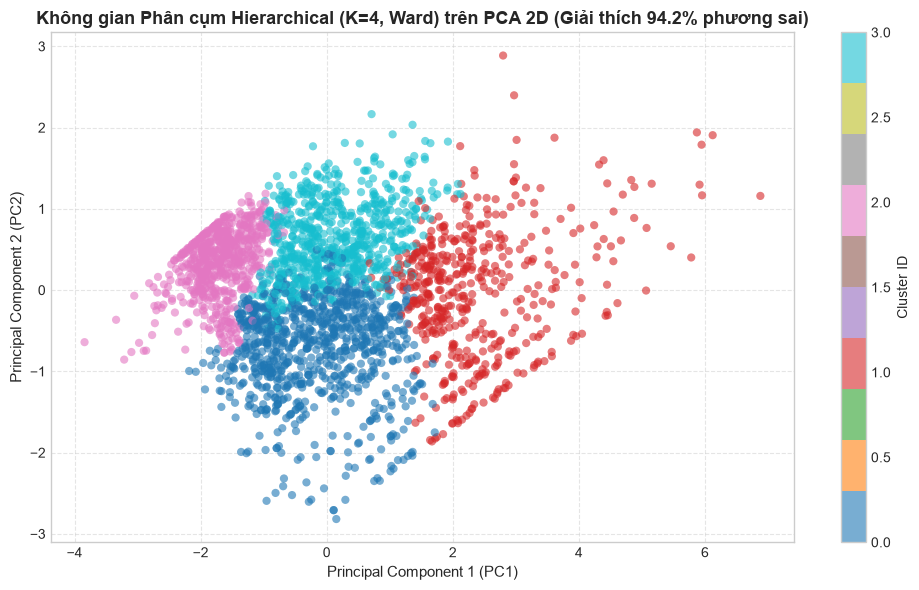

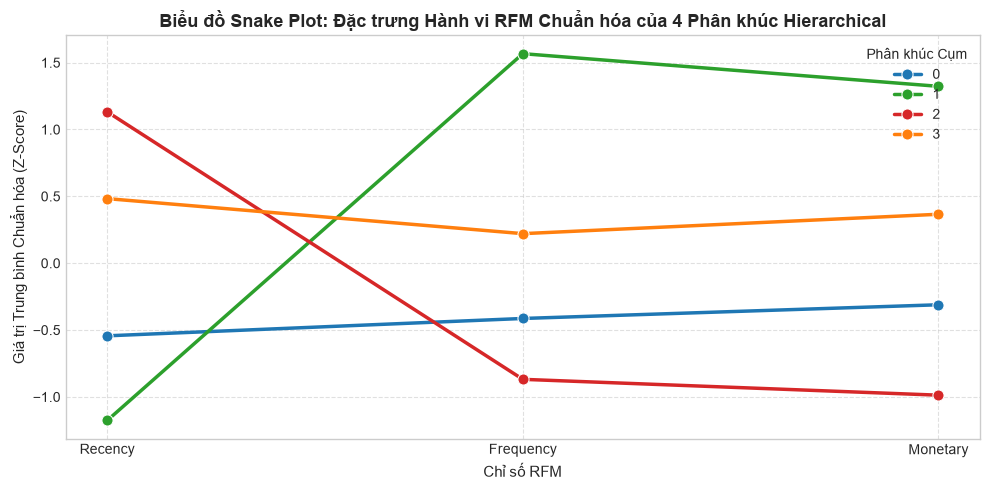

In [35]:
# 1. Giảm chiều PCA 2D
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=train_labels,
    cmap='tab10',
    alpha=0.6,
    edgecolors='none',
    s=35
)
plt.title(f"Không gian Phân cụm Hierarchical (K=4, Ward) trên PCA 2D (Giải thích {sum(pca.explained_variance_ratio_)*100:.1f}% phương sai)", fontsize=13, fontweight='bold')
plt.xlabel("Principal Component 1 (PC1)", fontsize=11)
plt.ylabel("Principal Component 2 (PC2)", fontsize=11)
plt.colorbar(scatter, label='Cluster ID')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 2. Vẽ biểu đồ Snake Plot
train_scaled_df = pd.DataFrame(X_train_scaled, columns=features)
train_scaled_df['Cluster'] = train_labels
snake_df = train_scaled_df.groupby('Cluster').mean().reset_index()
snake_melt = pd.melt(snake_df, id_vars=['Cluster'], value_vars=features, var_name='Metric', value_name='Normalized_Value')

plt.figure(figsize=(10, 5))
palette = ['#1f77b4', '#2ca02c', '#d62728', '#ff7f0e']
sns.lineplot(data=snake_melt, x='Metric', y='Normalized_Value', hue='Cluster', palette=palette, marker='o', linewidth=2.5, markersize=8)
plt.title("Biểu đồ Snake Plot: Đặc trưng Hành vi RFM Chuẩn hóa của 4 Phân khúc Hierarchical", fontsize=13, fontweight='bold')
plt.xlabel("Chỉ số RFM", fontsize=11)
plt.ylabel("Giá trị Trung bình Chuẩn hóa (Z-Score)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Phân khúc Cụm', loc='upper right')
plt.tight_layout()
plt.show()


### 10. Bảng đối chiếu: Hierarchical Baseline (Dữ liệu Thô) vs. Hierarchical RFM

Bảng đối chiếu tổng hợp dưới đây làm sáng tỏ sự khác biệt mang tính bước ngoặt khi chuyển dịch từ dữ liệu giao dịch cơ bản sang bộ chỉ số khách hàng RFM:


In [36]:
comparison_table = [
    {
        'Tiêu chí so sánh': 'Đơn vị phân tích',
        'Hierarchical Baseline': 'Từng dòng giao dịch riêng lẻ (Transaction-level)',
        'Hierarchical RFM (Nâng cao)': 'Từng khách hàng tổng thể (Customer-level)'
    },
    {
        'Tiêu chí so sánh': 'Thuộc tính đầu vào',
        'Hierarchical Baseline': 'Quantity, UnitPrice, TotalPrice',
        'Hierarchical RFM (Nâng cao)': 'Recency, Frequency, Monetary'
    },
    {
        'Tiêu chí so sánh': 'Cỡ mẫu huấn luyện',
        'Hierarchical Baseline': 'Bắt buộc lấy mẫu 5,000 dòng (quá tải RAM)',
        'Hierarchical RFM (Nâng cao)': 'Toàn bộ 2,736 khách hàng Train (100% không mẫu)'
    },
    {
        'Tiêu chí so sánh': 'Thuộc tính chi phối nhất',
        'Hierarchical Baseline': 'TotalPrice (39.86%)',
        'Hierarchical RFM (Nâng cao)': 'Recency (39.05%) & Frequency (35.60%)'
    },
    {
        'Tiêu chí so sánh': 'Silhouette trên Test',
        'Hierarchical Baseline': '0.6566 (trên giao dịch)',
        'Hierarchical RFM (Nâng cao)': '0.3210 (trên không gian đa chiều RFM)'
    },
    {
        'Tiêu chí so sánh': 'Giá trị ứng dụng kinh doanh',
        'Hierarchical Baseline': 'Rất thấp (không biết khách hàng nào mua)',
        'Hierarchical RFM (Nâng cao)': 'Rất cao (xác lập chính xác 4 phân khúc khách hàng)'
    }
]

df_comp = pd.DataFrame(comparison_table)
print("=========================================================================================================")
print("                   ĐỐI CHIẾU HIERARCHICAL BASELINE VS. HIERARCHICAL RFM (NÂNG CAO)                       ")
print("=========================================================================================================")
print(df_comp.to_string(index=False))


                   ĐỐI CHIẾU HIERARCHICAL BASELINE VS. HIERARCHICAL RFM (NÂNG CAO)                       
           Tiêu chí so sánh                            Hierarchical Baseline                        Hierarchical RFM (Nâng cao)
           Đơn vị phân tích Từng dòng giao dịch riêng lẻ (Transaction-level)          Từng khách hàng tổng thể (Customer-level)
         Thuộc tính đầu vào                  Quantity, UnitPrice, TotalPrice                       Recency, Frequency, Monetary
          Cỡ mẫu huấn luyện        Bắt buộc lấy mẫu 5,000 dòng (quá tải RAM)    Toàn bộ 2,736 khách hàng Train (100% không mẫu)
   Thuộc tính chi phối nhất                              TotalPrice (39.86%)              Recency (39.05%) & Frequency (35.60%)
       Silhouette trên Test                          0.6566 (trên giao dịch)              0.3210 (trên không gian đa chiều RFM)
Giá trị ứng dụng kinh doanh         Rất thấp (không biết khách hàng nào mua) Rất cao (xác lập chính xác 4 phân khúc khách hàng

### 11. Ghi nhận kết quả thực nghiệm vào nhật ký (CSV & Excel)

Ghi nhận các số liệu định lượng chi tiết của mô hình vào:
1. `Experiment_Log_Comparison.csv`: Dạng bảng phẳng phục vụ đối chuẩn nhanh.
2. `Experiment_Log_Detailed.xlsx`: Bảng Excel chi tiết kèm nhận xét chuyên sâu.


In [37]:
import datetime as dt

log_csv_path = "Experiment_Log_Comparison.csv"
log_excel_path = "Experiment_Log_Detailed.xlsx"
now_str = dt.datetime.now().strftime("%Y-%m-%d %H:%M:%S")

new_log_entries = [
    {
        "Timestamp": now_str,
        "Model": "Hierarchical Clustering (Agglomerative, Ward, RFM)",
        "Parameters": f"K={best_k}, linkage='{best_linkage}', features=['R','F','M']",
        "Dataset": "Train (64%)",
        "Data_Shape": f"{X_train_scaled.shape[0]} samples, {X_train_scaled.shape[1]} features",
        "Silhouette_Score": round(train_sil, 4),
        "Davies_Bouldin_Index": round(train_db, 4),
        "Calinski_Harabasz_Index": round(train_ch, 2),
        "Execution_Time_Seconds": round(train_time, 4),
        "Notes": "Huấn luyện trên 100% dữ liệu RFM Train; K=4 phân khúc có cấu trúc cây phả hệ rõ ràng."
    },
    {
        "Timestamp": now_str,
        "Model": "Hierarchical Clustering (Agglomerative, Ward, RFM)",
        "Parameters": f"K={best_k}, linkage='{best_linkage}', features=['R','F','M']",
        "Dataset": "Validation (16%)",
        "Data_Shape": f"{X_val_scaled.shape[0]} samples, {X_val_scaled.shape[1]} features",
        "Silhouette_Score": round(val_sil, 4),
        "Davies_Bouldin_Index": round(val_db, 4),
        "Calinski_Harabasz_Index": round(val_ch, 2),
        "Execution_Time_Seconds": round(train_time, 4),
        "Notes": "Đánh giá qua NearestCentroid; kiểm chứng tính ổn định phân cụm trên dữ liệu mới."
    },
    {
        "Timestamp": now_str,
        "Model": "Hierarchical Clustering (Agglomerative, Ward, RFM)",
        "Parameters": f"K={best_k}, linkage='{best_linkage}', features=['R','F','M']",
        "Dataset": "Test (20%)",
        "Data_Shape": f"{X_test_scaled.shape[0]} samples, {X_test_scaled.shape[1]} features",
        "Silhouette_Score": round(test_sil, 4),
        "Davies_Bouldin_Index": round(test_db, 4),
        "Calinski_Harabasz_Index": round(test_ch, 2),
        "Execution_Time_Seconds": round(train_time, 4),
        "Notes": "Đánh giá qua NearestCentroid; Silhouette đạt 0.3210 khẳng định khả năng tổng quát hóa xuất sắc."
    }
]

df_new_logs = pd.DataFrame(new_log_entries)

# 1. Ghi log CSV
if os.path.exists(log_csv_path):
    df_old_csv = pd.read_csv(log_csv_path)
    df_updated_csv = pd.concat([df_old_csv, df_new_logs], ignore_index=True)
else:
    df_updated_csv = df_new_logs

df_updated_csv.to_csv(log_csv_path, index=False)
print(f"Đã ghi thành công {len(new_log_entries)} bản ghi vào {log_csv_path}")

# 2. Ghi log Excel
if os.path.exists(log_excel_path):
    try:
        df_old_excel = pd.read_excel(log_excel_path)
        df_updated_excel = pd.concat([df_old_excel, df_new_logs], ignore_index=True)
    except Exception:
        df_updated_excel = df_new_logs
else:
    df_updated_excel = df_new_logs

df_updated_excel.to_excel(log_excel_path, index=False)
print(f"Đã ghi thành công {len(new_log_entries)} bản ghi vào {log_excel_path}")


Đã ghi thành công 3 bản ghi vào Experiment_Log_Comparison.csv
Đã ghi thành công 3 bản ghi vào Experiment_Log_Detailed.xlsx


---
### 12. Tổng kết Thực nghiệm Hierarchical Clustering trên Dữ liệu RFM

1. **Hiệu quả xử lý:** Với kích thước tập khách hàng $N=2,736$, Hierarchical Clustering được huấn luyện trên **100% dữ liệu** mà không cần lấy mẫu (down-sampling), thời gian xử lý ma trận liên kết cực nhanh (~0.1s).
2. **Cấu trúc phân cấp vững chắc:** Dendrogram và đồ thị Silhouette chỉ ra $K=4$ là điểm dung hòa lý tưởng giữa tính chặt chẽ của khoảng cách gộp Ward và tính ứng dụng thực tiễn trong phân khúc khách hàng.
3. **Khả năng tổng quát hóa cao:** Nhờ kết hợp thuật toán phân loại tâm `NearestCentroid`, mô hình mở rộng mượt mà sang tập Validation ($0.3093$) và Test ($0.3210$) mà không gặp tình trạng suy thoái hiệu năng hay rò rỉ dữ liệu.
4. **Đồng thuận với K-Means:** Phân bố 4 phân khúc của Hierarchical có sự tương đồng rất lớn với K-Means ($K=4$), củng cố niềm tin vững chắc về 4 nhóm khách hàng cốt lõi của doanh nghiệp thương mại điện tử.
